In [1]:
import numpy as np
from numpy.random import default_rng
from scipy.special import expit, logit

NUM_TESTERS = 100
NUM_SMART_TESTERS = 50
NUM_QUESTIONS = 250
NUM_HARD_QUESTIONS = 10

In [2]:
def make_rank_paradox_3pl_toy(
    Q_easy: int = NUM_QUESTIONS - NUM_HARD_QUESTIONS,
    Q_hard: int = NUM_HARD_QUESTIONS,
    N_normal: int = NUM_TESTERS - NUM_SMART_TESTERS,
    N_smart: int = NUM_SMART_TESTERS,
    a_easy: float = 0.3, 
    a_hard: float = 3.5,
    b_easy: float = -1.0, 
    b_hard: float = 3.0,
    c_val: float = 0.001,
    theta_normal: float = 2.0,
    theta_smart: float = 3.0,
    seed: int = 0,
):
    """Rank Paradox Toy 3PL data.
    """
    
    rng = default_rng(seed)

    # Ground truth parameters
    theta_j_true = np.array([theta_smart] * N_smart + [theta_normal] * N_normal)
    a_i_true = np.array([a_hard] * Q_hard + [a_easy] * Q_easy)
    b_i_true = np.array([b_hard] * Q_hard + [b_easy] * Q_easy)
    c_i_true = np.full(Q_hard+Q_easy, float(c_val))                                    # (Q,)

    
    # Linear predictor & probabilities
    eta_ij = a_i_true[:, None] * (theta_j_true[None, :] - b_i_true[:, None])
             
    eta_ij = np.clip(eta_ij, -40, 40)
    P_ij = c_i_true[:, None] + (1.0 - c_i_true[:, None]) * expit(eta_ij)

    # Draw responses
    Y_ij = rng.binomial(1, P_ij).astype(float)

    return dict(
        Y_ij=Y_ij, c_i_true=c_i_true,
        a_i_true=a_i_true, b_i_true=b_i_true,
        theta_j_true=theta_j_true, P_ij=P_ij,
        seed=seed
    )

In [3]:
rank_toy = make_rank_paradox_3pl_toy(seed=11) # seed 21 for extreme mistakes on one smart tester
print(rank_toy["Y_ij"].shape)

tester_scores = rank_toy["Y_ij"].sum(axis=0)
smart_tester_scores = tester_scores[:NUM_SMART_TESTERS]
normal_tester_scores = tester_scores[NUM_SMART_TESTERS:]
min_smart_score = smart_tester_scores.min()
num_swap_rank = normal_tester_scores[normal_tester_scores > min_smart_score].shape[0]

print(f'there are {num_swap_rank} normal testers getting higher scores than smart testers')

(250, 100)
there are 22 normal testers getting higher scores than smart testers


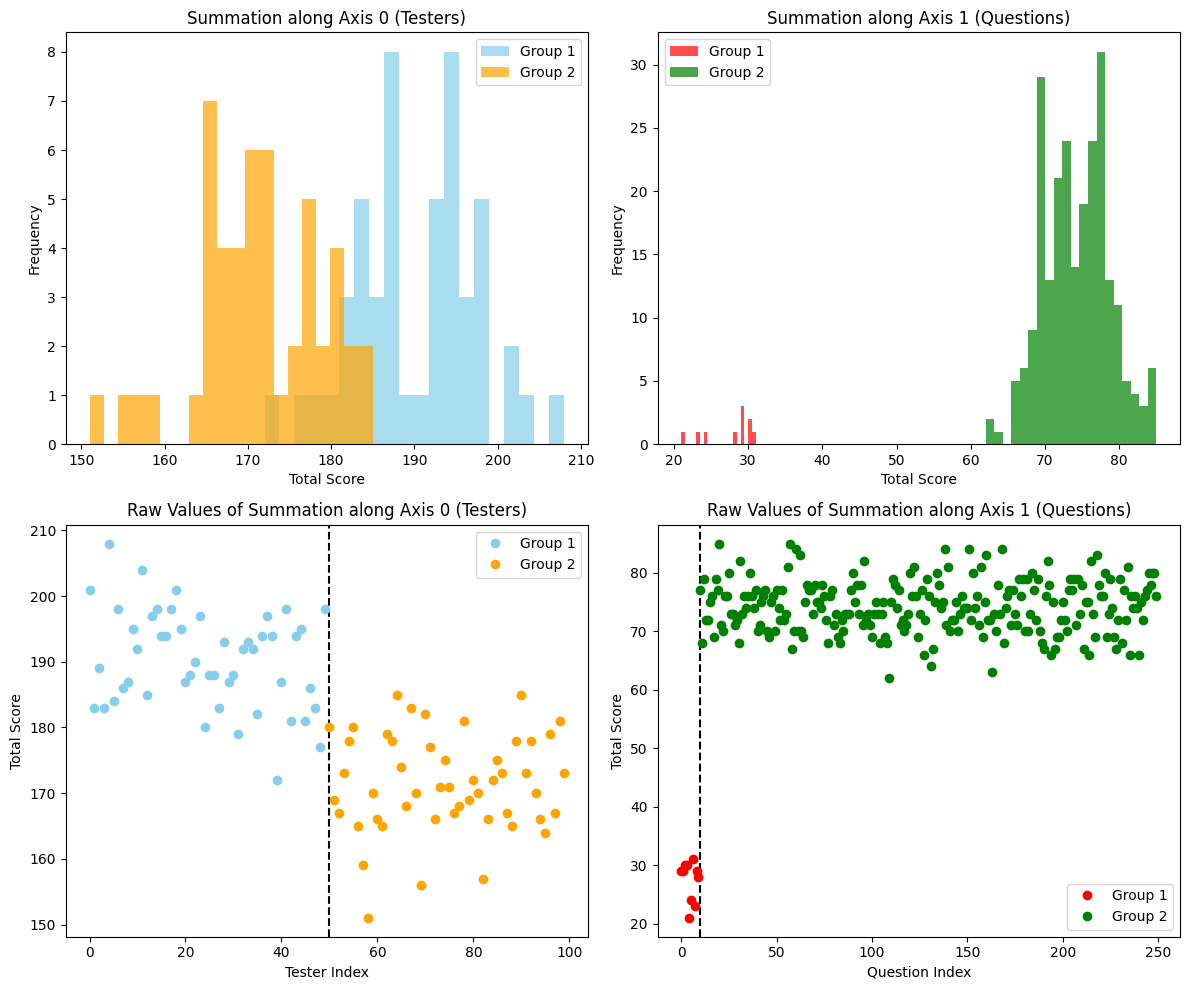

In [4]:
from reasoning_aware_irt.utils import visualize_score_matrix
visualize_score_matrix(rank_toy['Y_ij'], tester_threshold_idx=50, question_threshold_idx=10)

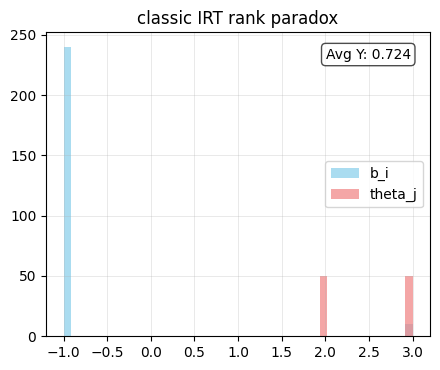

In [5]:
from reasoning_aware_irt.utils import plot_multiple_b_theta_histograms
_, _ = plot_multiple_b_theta_histograms([rank_toy], ['classic IRT rank paradox'], plots_per_row=2, avg_Y_list=[rank_toy['Y_ij'].mean()])

## Informaiton visualization
Warning : the below plottings use Plotly which quite resource-intensive to free-compute like Codespace

In [ ]:
from reasoning_aware_irt.utils import create_test_information_figure, create_item_information_figure, plot_test_characteristic_curve

item_indices_to_plot = [0, 10, 99, 149, 199]
item_names = [str(i) for i in item_indices_to_plot]

a = np.array([rank_toy['a_i_true'][i] for i in item_indices_to_plot])
b = np.array([rank_toy['b_i_true'][i] for i in item_indices_to_plot])
c = np.array([rank_toy['c_i_true'][i] for i in item_indices_to_plot])

fig = create_test_information_figure(a,b,c,item_names)
fig.show()

In [ ]:
item_indices_to_plot = [149, 199]
item_names = [str(i) for i in item_indices_to_plot]

a = np.array([rank_toy['a_i_true'][i] for i in item_indices_to_plot])
b = np.array([rank_toy['b_i_true'][i] for i in item_indices_to_plot])
c = np.array([rank_toy['c_i_true'][i] for i in item_indices_to_plot])

fig = create_item_information_figure(a,b,c,item_names)
fig.show()

In [ ]:
fig = plot_test_characteristic_curve(rank_toy)
fig.show()

# EM

In [6]:
from reasoning_aware_irt.classic_irt_em import IRT3PLCalibrator
from reasoning_aware_irt.classic_irt_em import ClassicCalibrationData, ClassicCalibrationConfig

data = ClassicCalibrationData(Y_ij=rank_toy["Y_ij"], c_i=rank_toy["c_i_true"])
cfg = ClassicCalibrationConfig(
    gh_nodes=100, tol=1e-3,
    max_iter=200, verbose=True,
)

calibrator = IRT3PLCalibrator(cfg)


In [7]:
a0, b0 = calibrator.init_params(rank_toy['Y_ij'])
print(b0[:20])


[ 0.89538405  0.89538405  0.84729786  0.84729786  1.32492541  1.15267951
  0.8001193   1.20831121  0.89538405  0.94446161 -1.20831121 -0.7537718
 -1.32492541 -0.94446161 -0.94446161 -1.09861229 -1.15267951 -0.8001193
 -1.32492541 -1.20831121]


In [8]:
fit_results = calibrator.fit(data)

iter=  1  LL=-13822.731225  dLL=2.386e+02
iter=  2  LL=-13792.027885  dLL=3.070e+01
iter=  3  LL=-13779.590796  dLL=1.244e+01
iter=  4  LL=-13775.532769  dLL=4.058e+00
iter=  5  LL=-13774.145449  dLL=1.387e+00
iter=  6  LL=-13773.697444  dLL=4.480e-01
iter=  7  LL=-13773.727922  dLL=-3.048e-02
iter=  8  LL=-13773.991771  dLL=-2.638e-01
iter=  9  LL=-13774.328736  dLL=-3.370e-01
iter= 10  LL=-13774.865314  dLL=-5.366e-01
iter= 11  LL=-13775.447828  dLL=-5.825e-01
iter= 12  LL=-13776.043725  dLL=-5.959e-01
iter= 13  LL=-13776.617577  dLL=-5.739e-01
iter= 14  LL=-13777.173889  dLL=-5.563e-01
iter= 15  LL=-13777.673504  dLL=-4.996e-01
iter= 16  LL=-13778.120219  dLL=-4.467e-01
iter= 17  LL=-13778.509451  dLL=-3.892e-01
iter= 18  LL=-13778.841577  dLL=-3.321e-01
iter= 19  LL=-13779.117573  dLL=-2.760e-01
iter= 20  LL=-13779.324892  dLL=-2.073e-01
iter= 21  LL=-13779.524870  dLL=-2.000e-01
iter= 22  LL=-13779.677894  dLL=-1.530e-01
iter= 23  LL=-13779.811148  dLL=-1.333e-01
iter= 24  LL=-137

[2.28469432 3.12090498 3.43806575 3.13115451 1.9579305  1.5690281
 2.81237653 2.54428969 2.04089304 2.69687282 0.12609714 0.27731579
 0.09971646 0.182657   0.3857912  0.24414178 0.43033965 0.05
 0.08944919 0.15726366]

[  0.6953578    0.6534995    0.61954405   0.62568665   1.02623706
   1.00879509   0.60672966   0.86603952   0.71955038   0.69840429
  -9.55464213  -2.75006113 -13.19400415  -5.18758399  -2.50910088
  -4.53765794  -2.76040703 -15.69023426 -14.70919555  -7.69131304]


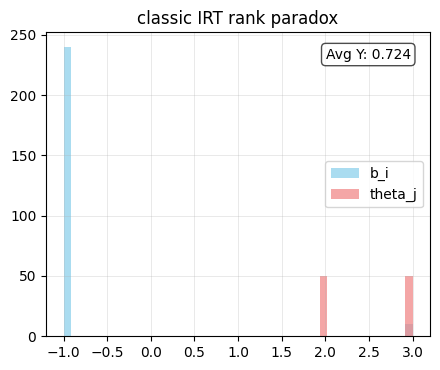

In [9]:
print(fit_results.a_i[:20])
print()
print(fit_results.b_i[:20])

_, _ = plot_multiple_b_theta_histograms([rank_toy], ['classic IRT rank paradox'], plots_per_row=2, avg_Y_list=[rank_toy['Y_ij'].mean()])

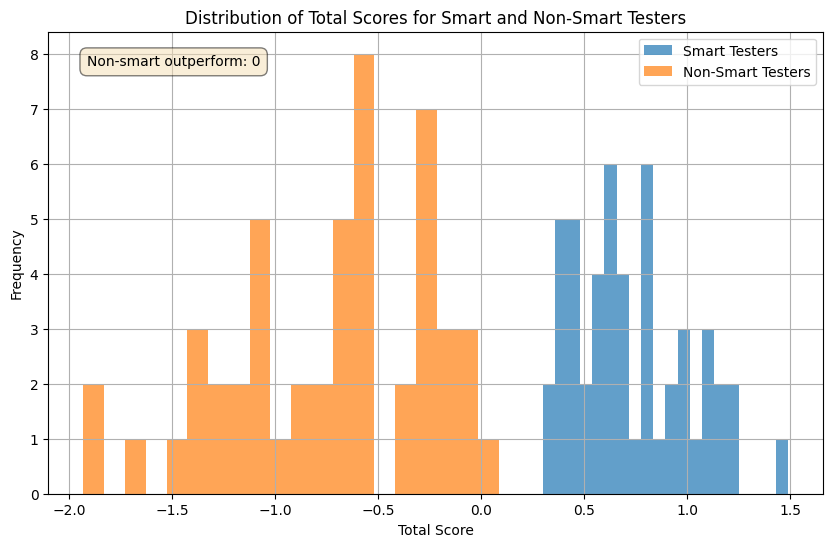

In [10]:
import matplotlib.pyplot as plt

def visualize_tester_scores(total_scores, smart_tester_indices=None):
    if smart_tester_indices is None:
        smart_tester_indices = np.arange(50)  # Default to the first 50 testers

    smart_tester_scores = total_scores[smart_tester_indices]
    non_smart_tester_indices = np.setdiff1d(np.arange(total_scores.shape[0]), smart_tester_indices)
    non_smart_tester_scores = total_scores[non_smart_tester_indices]

    plt.figure(figsize=(10, 6))
    plt.hist(smart_tester_scores, bins=20, alpha=0.7, label='Smart Testers')
    plt.hist(non_smart_tester_scores, bins=20, alpha=0.7, label='Non-Smart Testers')
    plt.xlabel('Total Score')
    plt.ylabel('Frequency')
    plt.title('Distribution of Total Scores for Smart and Non-Smart Testers')
    plt.legend()
    plt.grid(True)

    # Count outperforming non-smart testers
    outperforming_count = 0
    min_smart_score = smart_tester_scores.min()
    for non_smart_score in non_smart_tester_scores:
        if non_smart_score > min_smart_score:
            outperforming_count += 1

    # Display the information in a text box on the plot
    plt.text(0.05, 0.95, f'Non-smart outperform: {outperforming_count}', transform=plt.gca().transAxes,
             fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.5))


    plt.show()


# Example usage with the rank_toy data:
smart_tester_indices = np.arange(50)
visualize_tester_scores(fit_results.theta_j_mean, smart_tester_indices)

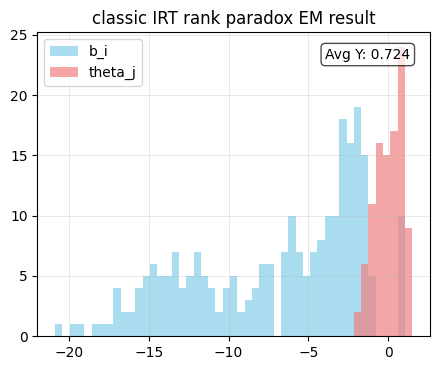

In [11]:
_, _ = plot_multiple_b_theta_histograms([fit_results], ['classic IRT rank paradox EM result'], plots_per_row=2, avg_Y_list=[rank_toy['Y_ij'].mean()])